### **Fórmulas Matemáticas Puras**

#### **1. Sigmoide (σ)**
$$
\sigma(x) = \frac{1}{1 + e^{-x}}
$$
- **Rango de salida:** \((0, 1)\)
- **Característica:** Transforma cualquier valor real a una probabilidad entre 0 y 1.

---

#### **2. ReLU (Rectified Linear Unit)**
$$
\text{ReLU}(x) = \max(0, x)
$$
- **Rango de salida:** $[0, +\infty)$
- **Característica:** Devuelve 0 para valores negativos y la identidad para positivos.

---

#### **3. Tanh (Tangente Hiperbólica)**
$$
\tanh(x) = \frac{e^{x} - e^{-x}}{e^{x} + e^{-x}}
$$
- **Rango de salida:** \((-1, 1)\)
- **Característica:** Versión centrada de la sigmoide (similar pero entre -1 y 1).


Genraedos
sogmoides
relu:
tanh:


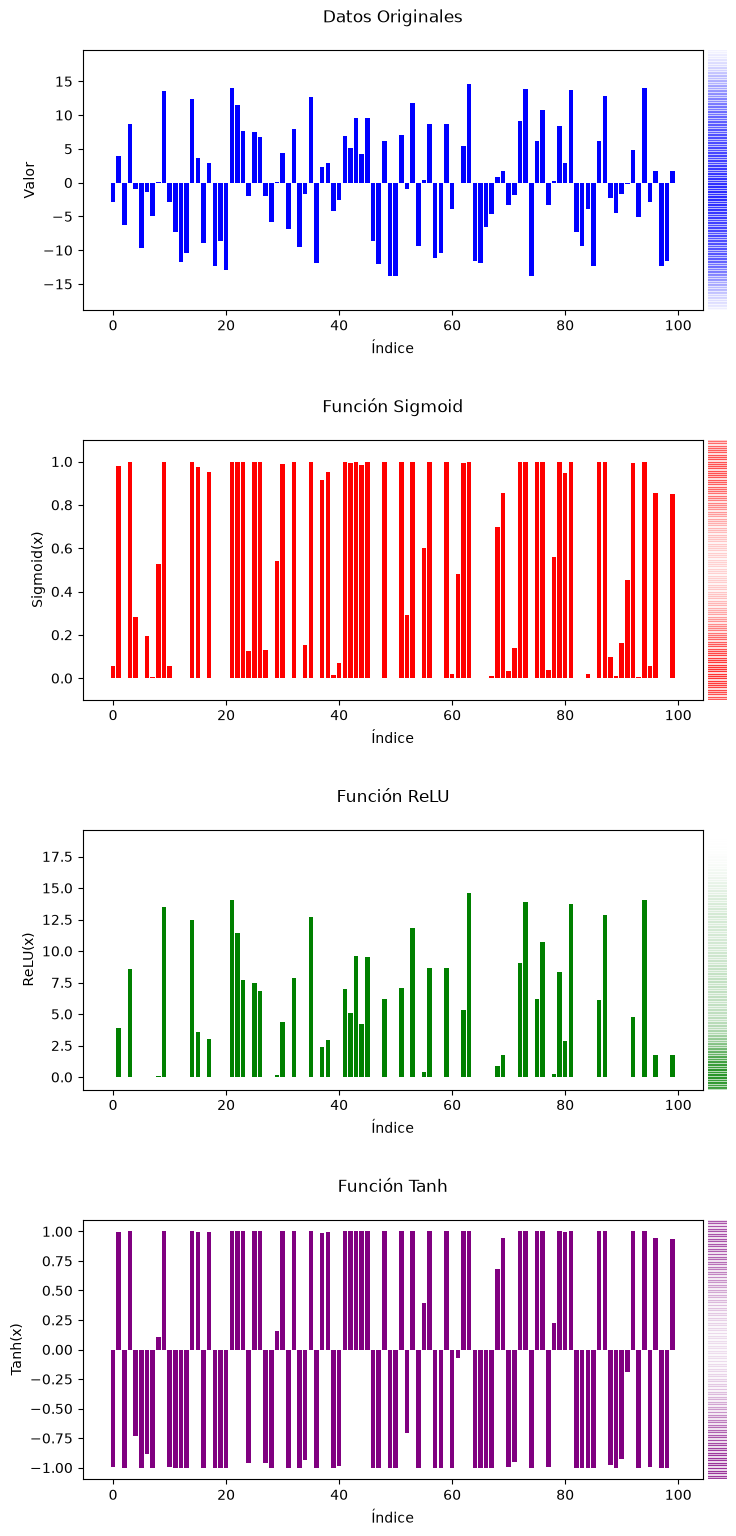

In [1]:
import math
import matplotlib.pyplot as plt
import random


datos = []
for _ in range(100):
    datos.append(random.random()*30-15)
print("Genraedos")
#print(datos)


def sigmoid(x):
    return 1 / (1 + math.exp(-x))

datos_sig = []
for aux in datos:
    datos_sig.append(sigmoid(aux))
print("sogmoides")
#print(datos_sig)


def relu(x):
    return max(0, x)

datos_relu = []
for aux in datos:
    datos_relu.append(relu(aux))
print("relu:")
#print(datos_relu)

def tanh(x):
    e_plus = math.exp(x)
    e_minus = math.exp(-x)
    return (e_plus - e_minus) / (e_plus + e_minus)

datos_tanh = []
for aux in datos:
    datos_tanh.append(tanh(aux))
print("tanh:")
#print(datos_tanh)


#--------------------------



# Crear figura con más altura
plt.figure(figsize=(8, 16))  # Aumenté la altura a 16

# Gráfico 1: Datos originales
plt.subplot(4, 1, 1)
plt.bar(range(len(datos)), datos, color='blue')
plt.title('Datos Originales', pad=20)  # pad añade espacio al título
plt.xlabel('Índice')
plt.ylabel('Valor')
plt.ylim(min(datos)-5, max(datos)+5)  # Espacio adicional arriba y abajo

# Gráfico 2: Sigmoid
plt.subplot(4, 1, 2)
plt.bar(range(len(datos_sig)), datos_sig, color='red')
plt.title('Función Sigmoid', pad=20)
plt.xlabel('Índice')
plt.ylabel('Sigmoid(x)')
plt.ylim(-0.1, 1.1)  # La sigmoid va de 0 a 1, añadimos margen

# Gráfico 3: ReLU
plt.subplot(4, 1, 3)
plt.bar(range(len(datos_relu)), datos_relu, color='green')
plt.title('Función ReLU', pad=20)
plt.xlabel('Índice')
plt.ylabel('ReLU(x)')
plt.ylim(-1, max(datos_relu)+5)  # Espacio para ver el cero y valores positivos

# Gráfico 4: Tanh
plt.subplot(4, 1, 4)
plt.bar(range(len(datos_tanh)), datos_tanh, color='purple')
plt.title('Función Tanh', pad=20)
plt.xlabel('Índice')
plt.ylabel('Tanh(x)')
plt.ylim(-1.1, 1.1)  # Tanh va de -1 a 1, con margen


#-----


# Añade esto JUSTO ANTES de plt.tight_layout(pad=3.0)

from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import pandas as pd
import seaborn as sns

# Configurar los 4 subplots originales para añadir densidades
axes = plt.gcf().get_axes()  # Obtiene todos los ejes de la figura actual

# Lista de tus datos y colores correspondientes
tus_datos = [datos, datos_sig, datos_relu, datos_tanh]
colores = ['blue', 'red', 'green', 'purple']

for ax, datos_actuales, color in zip(axes, tus_datos, colores):
    # Crear eje para la densidad (muy estrecho - 3% del ancho)
    divider = make_axes_locatable(ax)
    ax_dens = divider.append_axes("right", size="3%", pad=0.05, sharey=ax)

    # Convertir a DataFrame temporal para Seaborn
    df_temp = pd.DataFrame({'valores': datos_actuales})

    # Calcular densidad con KDE (versión compatible con listas)
    sns.kdeplot(data=df_temp, y='valores', color=color, fill=False, ax=ax_dens)

    # Obtener los datos del KDE para la transparencia
    line = ax_dens.lines[-1]
    x, y = line.get_data()
    densidad_norm = (x - x.min()) / (x.max() - x.min())

    # Limpiar y dibujar las líneas con transparencia
    ax_dens.clear()
    for y_val, alpha in zip(y, densidad_norm):
        ax_dens.axhline(y=y_val, color=color, alpha=alpha*0.8, linewidth=1)

    # Configuración visual minimalista
    ax_dens.set_xticks([])
    ax_dens.set_xlabel('')
    ax_dens.spines[:].set_visible(False)
    ax_dens.yaxis.set_visible(False)
    ax_dens.set_xlim(0, 1)

plt.tight_layout(pad=3.0)
#-----


# Ajustar espacio entre subplots
plt.tight_layout(pad=3.0)  # Más espacio entre subplots
plt.show()

